# Multi-Time Baldick Market

Two sequential day-ahead markets for the same multi-participant fleet as
[`Multi_Participant_Baldick.py`](../experiments/Multi_Participant_Baldick.py): day 1
clears the ordinary system, then day 2 clears as an **independent** market that starts
each storage owner exactly where day 1 left it -- its terminal SOC becomes day 2's `s0`.
This is *not* one connected multi-day optimization; it models a realistic day-ahead
operator that never sees tomorrow while clearing today, only today's own data plus
whatever physical state (SOC) storage happens to carry forward.

Day 2 differs from day 1 along two independent axes, both isolating a one-day-ahead
shock the market has no foresight into:

| case | day 2 RAC | day 2 willingness-to-pay |
|---|---|---|
| `multi_time_low_renewable` | x0.5 | x1.2 (storage values energy *more* when it expects scarcity) |
| `multi_time_high_renewable` | x1.5 | x0.7 (storage values energy *less* when it expects abundance) |

See [`../experiments/Multi_Time_Baldick.py`](../experiments/Multi_Time_Baldick.py) for
`next_day_system` (the SOC-carryover mechanics), `TerminalValueFunction.scaled` (the
willingness-to-pay re-pricing), and `run_multi_time_case`.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from experiments.Multi_Participant_Baldick import build_system
from experiments.Multi_Time_Baldick import MULTI_TIME_CASES, next_day_system
from markets.day_ahead import solve_day_ahead

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (9, 4)

system, terminal_values = build_system()
day1 = solve_day_ahead(system, terminal_values)
storage_wtp = [tv.marginal_values[0] for tv in terminal_values]

day2_systems = {}
day2_terminal_values = {}
day2_results = {}
for case_name, case in MULTI_TIME_CASES.items():
    day2_systems[case_name] = next_day_system(system, case.renewable_factor, day1.terminal_soc)
    day2_terminal_values[case_name] = tuple(tv.scaled(case.wtp_multiplier) for tv in terminal_values)
    day2_results[case_name] = solve_day_ahead(day2_systems[case_name], day2_terminal_values[case_name])

list(day2_results)

['multi_time_low_renewable', 'multi_time_high_renewable']

## Day 1 (shared baseline)

Identical to `Multi_Participant_Baldick.py`'s own single-day system -- shown here once
since both day-2 cases branch off the same day 1.

In [2]:
display(day1.to_owner_frame(system))
display(day1.to_profit_frame(system))
display(day1.to_dual_frame(system))
print(f"objective (net system cost, $):    {day1.objective:,.2f}")
print(f"ESS surplus total ($):             {day1.ess_surplus.sum():,.2f}")
print(f"terminal SOC (carried into day 2): {day1.terminal_soc.round(2)}")

Renewable (MW)                                     Thermal (MW)  \
            renewable_1 renewable_2 renewable_3 renewable_4    thermal_1   
Interval                                                                   
1               192.125     199.532     170.532     159.732        0.000   
2                95.036     105.562      98.119      95.690        0.000   
3               519.594     446.231     449.302     498.060        0.000   
4               514.275     356.895       0.000     504.532        0.000   
5                25.211      21.198      25.314      21.940        0.000   
6                 0.000       0.000       0.000       0.000        0.000   

                                       ESS discharge (MW)                      \
         thermal_2 thermal_3 thermal_4          storage_1 storage_2 storage_3   
Interval                                                                        
1            0.000     0.000     0.000              0.000     0.000     0.000   
2          115.864     0.000     0.000            200.000    89.729     0.000   
3            0.000     0.000     0.000              0.000     0.000     0.000   
4            0.000     0.000     0.000              0.000     0.000     0.000   
5          138.784     0.000   100.263             67.290   200.000   200.000   
6          138.784    28.243   100.263            132.710     0.000     0.000   

                   ESS charge (MW)                               SOC (MWh)  \
         storage_4       storage_1 storage_2 storage_3 storage_4 storage_1   
Interval                                                                     
1            0.000         222.222    99.699     0.000     0.000   800.000   
2            0.000           0.000     0.000     0.000     0.000     0.000   
3            0.000         222.222   222.222    46.520   222.222   800.000   
4            0.000           0.000     0.000   175.702     0.000   800.000   
5            0.000           0.000     0.000     0.000     0.000   530.840   
6            0.000           0.000     0.000     0.000     0.000     0.000   

                                       Price ($/MWh)  
         storage_2 storage_3 storage_4                
Interval                                              
1          358.916     0.000     0.000        35.680  
2            0.000     0.000     0.000        41.756  
3          800.000   167.473   800.000         0.000  
4          800.000   800.000   800.000         0.000  
5            0.000     0.000   800.000        61.207  
6            0.000     0.000   800.000        61.207

,Profit ($)
thermal_1,0.000
thermal_2,"21,595.900"
thermal_3,0.000
thermal_4,"1,259.300"
renewable_1,"49,466.040"
renewable_2,"51,298.780"
renewable_3,"46,924.400"
renewable_4,"44,151.260"
storage_1,"47,276.710"
storage_2,"47,276.710"


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh) [storage_1],40.756,40.756,1.111,1.111,60.207,60.207
ν̄ -- SOC upper-bound dual ($/MWh) [storage_1],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_1],0.000,0.000,39.645,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_2],40.756,40.756,1.111,1.111,60.207,60.207
ν̄ -- SOC upper-bound dual ($/MWh) [storage_2],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_2],0.000,0.000,39.645,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_3],40.756,1.111,1.111,1.111,60.207,60.207
ν̄ -- SOC upper-bound dual ($/MWh) [storage_3],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_3],0.000,39.645,0.000,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_4],40.756,40.756,1.111,1.111,69.119,69.119


objective (net system cost, $):    56,864.51
ESS surplus total ($):             212,941.24
terminal SOC (carried into day 2): [  0.   0.   0. 800.]


## Day 2's re-priced willingness-to-pay, by owner

Each owner's day-2 bid is its own day-1 value scaled by that case's multiplier --
applied uniformly, so the owners' *relative* order never changes, only how far each
sits from day 2's own clearing prices.

In [3]:
wtp_table = pd.DataFrame(
    {
        "day 1 w ($/MWh)": storage_wtp,
        **{
            f"{case_name} w ($/MWh)": [tv.marginal_values[0] for tv in day2_terminal_values[case_name]]
            for case_name in MULTI_TIME_CASES
        },
    },
    index=[s.name for s in system.storages],
)
display(wtp_table.round(2))

,day 1 w ($/MWh),multi_time_low_renewable w ($/MWh),multi_time_high_renewable w ($/MWh)
storage_1,25.000,30.000,17.500
storage_2,40.000,48.000,28.000
storage_3,55.000,66.000,38.500
storage_4,90.000,108.000,63.000


## Why an unshocked day-2 reference matters

Day 2 doesn't start where day 1 started -- storage_4 (`w`=\$90/MWh) carries its full
800 MWh cap into day 2 instead of the empty tank day 1 began with, so *even a fully
unscaled* day-2 clearing (renewable factor 1.0, willingness-to-pay factor 1.0) won't
reproduce day 1's own objective. To isolate what each case's shock itself costs, compare
it against this unshocked reference -- same SOC carryover, nothing else changed --
rather than against day 1.

In [4]:
day2_ref_system = next_day_system(system, 1.0, day1.terminal_soc)
day2_ref = solve_day_ahead(day2_ref_system, terminal_values)

print(f"day 1 objective:                ${day1.objective:>12,.2f}")
print(f"day 2 unshocked (both factors 1.0): ${day2_ref.objective:>12,.2f}")
print(f"day 2 unshocked terminal SOC:    {day2_ref.terminal_soc.round(1)}")
print()
for case_name, case in MULTI_TIME_CASES.items():
    r = day2_results[case_name]
    print(
        f"{case_name:26s} (RAC x{case.renewable_factor}, WTP x{case.wtp_multiplier}): "
        f"${r.objective:>12,.2f}  ({r.objective / day2_ref.objective:.2f}x the unshocked day-2 reference)"
    )

day 1 objective:                $   56,864.51
day 2 unshocked (both factors 1.0): $  109,601.95
day 2 unshocked terminal SOC:    [  0.   0.   0. 800.]

multi_time_low_renewable   (RAC x0.5, WTP x1.2): $  492,681.70  (4.50x the unshocked day-2 reference)
multi_time_high_renewable  (RAC x1.5, WTP x0.7): $   96,587.74  (0.88x the unshocked day-2 reference)


Both ratios come out **identical** to what a renewable-factor-only shock would give
(see [`../experiments/Multi_Time_Baldick.py`](../experiments/Multi_Time_Baldick.py)'s
history): at these multiplier sizes, willingness-to-pay re-pricing doesn't actually move
the dispatch here. The reason is visible in the table above -- storage_4's day-1 bid
(\$90/MWh) already sits far above every day-2 price this fleet ever clears at (day-2
prices never exceed roughly \$70/MWh across either case), and storage_1-3's bids
already sit far below. A x1.2/x0.7 re-pricing isn't large enough to cross the price band
either owner is already comfortably on one side of, so each owner reaches the exact same
terminal SOC it would have without any re-pricing at all -- confirmed directly: scaling
storage_4's bid down to x0.5 (well past x0.7) is what it actually takes to flip its
day-2 choice away from holding its cap. The mechanism is real and does bind at more
extreme multipliers; it just isn't the binding constraint for *this* fleet at x1.2/x0.7.

## Day 2 -- low renewable (×0.5 RAC, ×1.2 willingness-to-pay)

In [5]:
name = "multi_time_low_renewable"
sys_low, res_low = day2_systems[name], day2_results[name]
display(res_low.to_owner_frame(sys_low))
display(res_low.to_profit_frame(sys_low))
display(res_low.to_dual_frame(sys_low))
print(f"objective (net system cost, $): {res_low.objective:,.2f}")
print(f"ESS surplus total ($):          {res_low.ess_surplus.sum():,.2f}")

Renewable (MW)                                     Thermal (MW)  \
            renewable_1 renewable_2 renewable_3 renewable_4    thermal_1   
Interval                                                                   
1                96.062      99.766      85.266      79.866        0.000   
2                47.518      52.781      49.059      47.845      131.255   
3               259.797     223.115     224.651     249.030        0.000   
4               257.137     240.847     255.425     252.266        0.000   
5                12.605      10.599      12.657      10.970      131.255   
6                 0.000       0.000       0.000       0.000       45.945   

                                       ESS discharge (MW)                      \
         thermal_2 thermal_3 thermal_4          storage_1 storage_2 storage_3   
Interval                                                                        
1          138.784    97.613   100.263              0.000     0.000     0.000   
2          138.784   115.008   100.263              0.000     0.000     0.000   
3          138.784     4.359   100.263              0.000     0.000     0.000   
4          138.784    85.817   100.263              0.000     0.000     0.000   
5          138.784   115.008   100.263              0.000    67.859   200.000   
6          138.784   115.008   100.263              0.000     0.000     0.000   

                   ESS charge (MW)                               SOC (MWh)  \
         storage_4       storage_1 storage_2 storage_3 storage_4 storage_1   
Interval                                                                     
1            0.000           0.000    75.398   222.222     0.000     0.000   
2          117.487           0.000     0.000     0.000     0.000     0.000   
3            0.000           0.000     0.000     0.000     0.000     0.000   
4            0.000           0.000     0.000     0.000   130.541     0.000   
5            0.000           0.000     0.000     0.000     0.000     0.000   
6            0.000           0.000     0.000     0.000     0.000     0.000   

                                       Price ($/MWh)  
         storage_2 storage_3 storage_4                
Interval                                              
1          271.434   800.000   800.000        61.207  
2          271.434   800.000   330.054        70.119  
3          271.434   800.000   330.054        61.207  
4          271.434   800.000   800.000        61.207  
5            0.000     0.000   800.000        70.119  
6            0.000     0.000   800.000        61.916

,Profit ($)
thermal_1,"8,613.360"
thermal_2,"75,075.910"
thermal_3,"8,525.670"
thermal_4,"11,210.520"
renewable_1,"166,942.000"
renewable_2,"155,793.180"
renewable_3,"155,721.640"
renewable_4,"158,780.900"
storage_1,0.000
storage_2,0.000


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh) [storage_1],69.119,69.119,69.119,69.119,69.119,69.119
ν̄ -- SOC upper-bound dual ($/MWh) [storage_1],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_1],0.000,0.000,0.000,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_2],69.119,69.119,69.119,69.119,69.119,69.119
ν̄ -- SOC upper-bound dual ($/MWh) [storage_2],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_2],0.000,0.000,0.000,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_3],69.119,69.119,69.119,69.119,69.119,69.119
ν̄ -- SOC upper-bound dual ($/MWh) [storage_3],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_3],0.000,0.000,0.000,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_4],60.207,69.119,69.119,69.119,69.907,69.907


objective (net system cost, $): 492,681.70
ESS surplus total ($):          -0.00


## Day 2 -- high renewable (×1.5 RAC, ×0.7 willingness-to-pay)

In [6]:
name = "multi_time_high_renewable"
sys_high, res_high = day2_systems[name], day2_results[name]
display(res_high.to_owner_frame(sys_high))
display(res_high.to_profit_frame(sys_high))
display(res_high.to_dual_frame(sys_high))
print(f"objective (net system cost, $): {res_high.objective:,.2f}")
print(f"ESS surplus total ($):          {res_high.ess_surplus.sum():,.2f}")

Renewable (MW)                                     Thermal (MW)  \
            renewable_1 renewable_2 renewable_3 renewable_4    thermal_1   
Interval                                                                   
1               271.973     299.298     255.798     239.598        0.000   
2               142.554     158.343     147.179     143.535        0.000   
3               779.391       0.000     429.931       0.000        0.000   
4               771.413     650.810       0.000       0.000        0.000   
5                37.816      31.797      37.971      32.910        0.000   
6                 0.000       0.000       0.000       0.000        0.000   

                                       ESS discharge (MW)                      \
         thermal_2 thermal_3 thermal_4          storage_1 storage_2 storage_3   
Interval                                                                        
1            0.000     0.000     0.000              0.000     0.000     0.000   
2            0.000     0.000     0.000              0.000     0.000     8.389   
3            0.000     0.000     0.000              0.000     0.000     0.000   
4            0.000     0.000     0.000              0.000     0.000     0.000   
5          138.784     0.000    81.674             39.047   200.000   200.000   
6          138.784     0.000   100.263            160.953     0.000     0.000   

                   ESS charge (MW)                               SOC (MWh)  \
         storage_4       storage_1 storage_2 storage_3 storage_4 storage_1   
Interval                                                                     
1            0.000         222.222   222.222   222.222     0.000   800.000   
2          200.000           0.000     0.000     0.000     0.000   800.000   
3            0.000           0.000     0.000     9.322     0.000   800.000   
4            0.000           0.000     0.000     0.000   222.222   800.000   
5            0.000           0.000     0.000     0.000     0.000   643.812   
6            0.000           0.000     0.000     0.000     0.000     0.000   

                                       Price ($/MWh)  
         storage_2 storage_3 storage_4                
Interval                                              
1          800.000   800.000   800.000         0.000  
2          800.000   766.442     0.000         2.111  
3          800.000   800.000     0.000         0.000  
4          800.000   800.000   800.000         0.000  
5            0.000     0.000   800.000        59.637  
6            0.000     0.000   800.000        59.637

,Profit ($)
thermal_1,0.000
thermal_2,"19,852.770"
thermal_3,0.000
thermal_4,0.000
renewable_1,"10,224.840"
renewable_2,"8,922.230"
renewable_3,"10,300.750"
renewable_4,"9,062.690"
storage_1,"46,020.710"
storage_2,"46,020.710"


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh) [storage_1],1.111,1.111,1.111,1.111,58.637,58.637
ν̄ -- SOC upper-bound dual ($/MWh) [storage_1],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_1],0.000,0.000,0.000,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_2],1.111,1.111,1.111,1.111,58.637,58.637
ν̄ -- SOC upper-bound dual ($/MWh) [storage_2],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_2],0.000,0.000,0.000,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_3],1.111,1.111,1.111,1.111,58.637,58.637
ν̄ -- SOC upper-bound dual ($/MWh) [storage_3],0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh) [storage_3],0.000,0.000,0.000,0.000,0.000,0.000
π -- SOC costate ($/MWh) [storage_4],-1.000,1.111,1.111,1.111,58.637,58.637


objective (net system cost, $): 96,587.74
ESS surplus total ($):          138,062.13


## System-wide dispatch stack, with clearing price -- full two-day view

Day 1's and each case's day-2 dispatch are concatenated purely for this plot -- they
were cleared as two separate markets, not jointly optimized. The dotted vertical line
marks the handoff: everything left of it is day 1's own dispatch (shared by both
panels), everything right of it is that case's independently-cleared day 2.

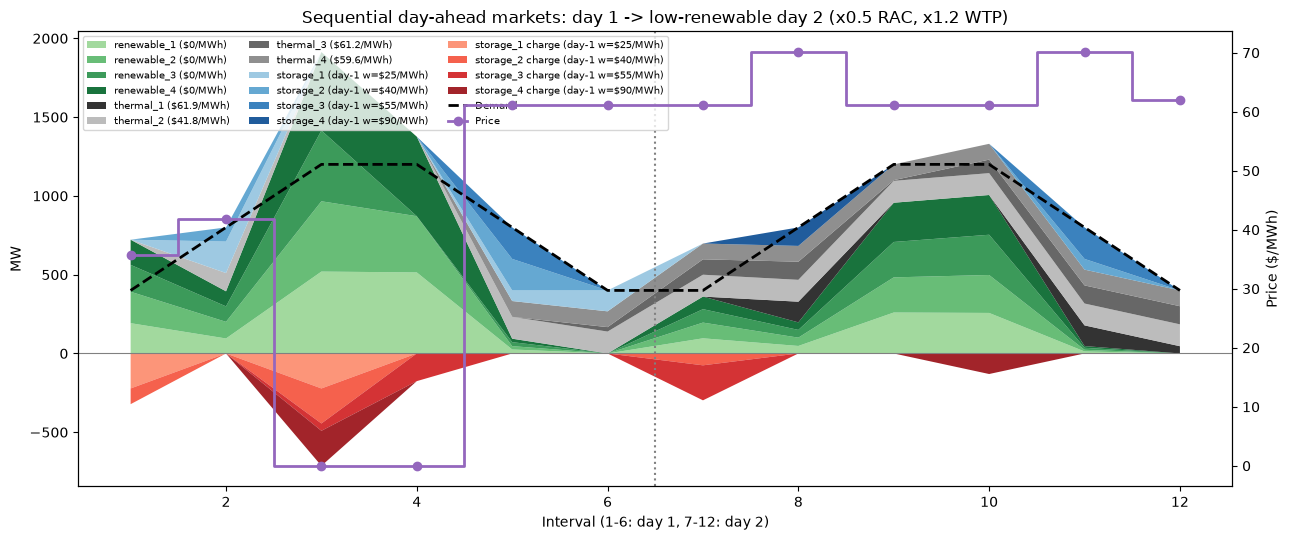

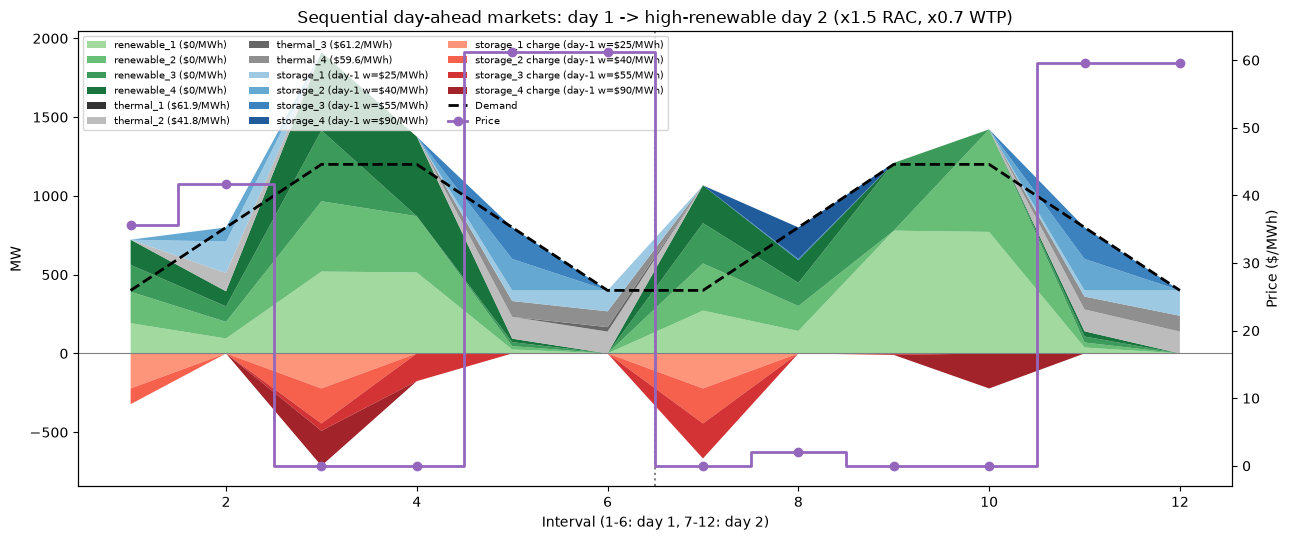

In [7]:
def rank_colors(values, cmap):
    """Map `values` to shades of `cmap`: lighter for lower values, darker for higher --
    independent of `values`'s own order, unlike indexing a linspace by position."""
    order = np.argsort(values)
    colors = np.empty((len(values), 4))
    colors[order] = cmap(np.linspace(0.4, 0.9, len(values)))
    return colors


def plot_two_day_stack(day2_system, day2_result, title):
    hours = range(1, 2 * system.T + 1)

    renewable = np.concatenate([day1.renewable, day2_result.renewable], axis=1)
    thermal = np.concatenate([day1.thermal, day2_result.thermal], axis=1)
    discharge = np.concatenate([day1.discharge, day2_result.discharge], axis=1)
    charge = np.concatenate([day1.charge, day2_result.charge], axis=1)
    price = np.concatenate([day1.price, day2_result.price])
    demand = list(system.demand) + list(day2_system.demand)

    renewable_colors = rank_colors([g.cost for g in system.renewables], plt.cm.Greens)
    thermal_colors = rank_colors([g.cost for g in system.thermal], plt.cm.Greys)
    discharge_colors = rank_colors(storage_wtp, plt.cm.Blues)
    charge_colors = rank_colors(storage_wtp, plt.cm.Reds)

    renewable_labels = [f"{g.name} (${g.cost:.0f}/MWh)" for g in system.renewables]
    thermal_labels = [f"{g.name} (${g.cost:.1f}/MWh)" for g in system.thermal]
    discharge_labels = [f"{s.name} (day-1 w=${w:.0f}/MWh)" for s, w in zip(system.storages, storage_wtp)]
    charge_labels = [f"{s.name} charge (day-1 w=${w:.0f}/MWh)" for s, w in zip(system.storages, storage_wtp)]

    supply_series = list(renewable) + list(thermal) + list(discharge)
    supply_labels = renewable_labels + thermal_labels + discharge_labels
    supply_colors = list(renewable_colors) + list(thermal_colors) + list(discharge_colors)

    fig, ax = plt.subplots(figsize=(13, 5.5))
    ax.stackplot(hours, *supply_series, labels=supply_labels, colors=supply_colors, alpha=0.9)
    ax.stackplot(hours, *(-charge), labels=charge_labels, colors=charge_colors, alpha=0.9)
    ax.plot(hours, demand, color="black", linewidth=2, linestyle="--", label="Demand")
    ax.axvline(system.T + 0.5, color="grey", linewidth=1.5, linestyle=":")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel("Interval (1-6: day 1, 7-12: day 2)")
    ax.set_ylabel("MW")

    ax_price = ax.twinx()
    ax_price.step(hours, price, where="mid", color="#9467BD", linewidth=2, marker="o", label="Price")
    ax_price.set_ylabel("Price ($/MWh)")

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax_price.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=7, ncol=3)
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


plot_two_day_stack(
    sys_low, res_low, "Sequential day-ahead markets: day 1 -> low-renewable day 2 (x0.5 RAC, x1.2 WTP)"
)
plot_two_day_stack(
    sys_high, res_high, "Sequential day-ahead markets: day 1 -> high-renewable day 2 (x1.5 RAC, x0.7 WTP)"
)

## Storage SOC across the day boundary

Legend labels show each owner's *day-1* willingness-to-pay -- day 2's actual bid is
that value re-priced by the case's multiplier (see the table above).

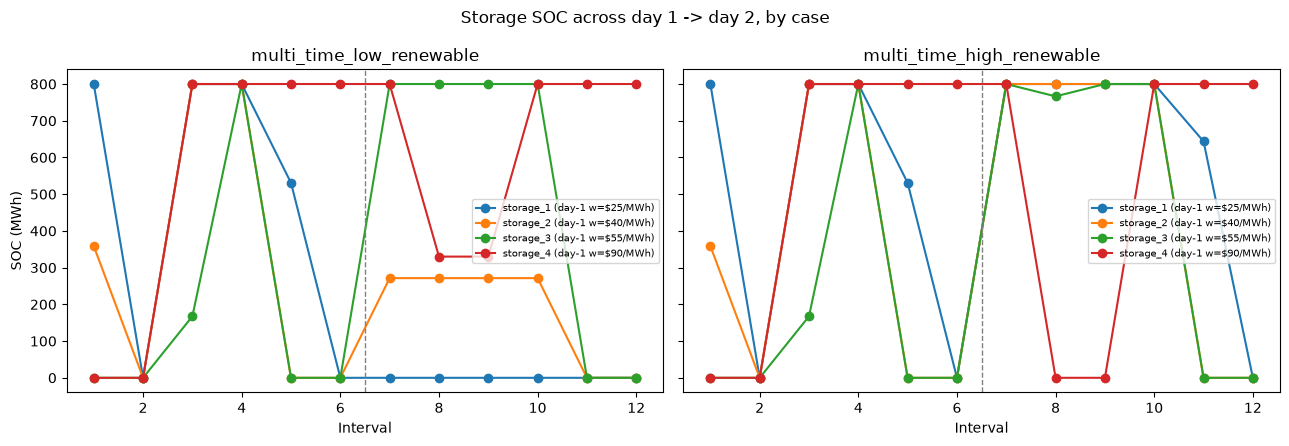

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
hours_2d = range(1, 13)

for ax, case_name in zip(axes, MULTI_TIME_CASES):
    res2 = day2_results[case_name]
    for i, s in enumerate(system.storages):
        soc_2day = np.concatenate([day1.soc[i], res2.soc[i]])
        ax.plot(hours_2d, soc_2day, marker="o", label=f"{s.name} (day-1 w=${storage_wtp[i]:.0f}/MWh)")
    ax.axvline(6.5, color="grey", linestyle="--", linewidth=1)
    ax.set_xlabel("Interval")
    ax.set_title(case_name)
    ax.legend(fontsize=7)

axes[0].set_ylabel("SOC (MWh)")
fig.suptitle("Storage SOC across day 1 -> day 2, by case")
fig.tight_layout()
plt.show()

## Next steps

This is a first, minimal instance of *sequential* (rather than jointly-optimized)
multi-day clearing -- exactly the visibility limitation a real day-ahead operator has,
now with two independent shock channels (renewable availability and willingness-to-pay)
that owners can't see coming. The willingness-to-pay re-pricing didn't bind at the
multipliers used here (see above) -- worth sweeping a range of multipliers, rather than
one fixed pair, to find where each owner's threshold actually sits. It's also a natural
stepping stone toward ROADMAP.md's DA-RT direction: chain a real-time re-dispatch after
each day-ahead clearing the same way day 2 chains after day 1 here, with `sbar_T` for
the next stage always inherited from the previous one's own ending SOC rather than
assumed.